### Cabeçalho do arquivo

**Disciplina:** Inteligência Artificial – 7º CC (Turma 7N) – Prof. Dr. Ivan Carlos Alcântara de Oliveira
**Projeto:** Coração em Alerta – Classificação de Doença Arterial Coronariana com Aprendizagem de Máquina e Explicabilidade
**Integrante:** Tiago Caspirro Cardoso (RA 10390562)

**Síntese do conteúdo do arquivo:** notebook da Parte 3 (N2 – Artigo Final) do Projeto de IA. Reúne a análise
exploratória condensada, a preparação dos dados e o protocolo experimental final: pré-processamento
reajustado dentro de cada partição, ajuste de hiperparâmetros, comparação de modelos por validação cruzada
aninhada com critério de seleção fixado previamente, escolha do limiar de decisão apenas com dados de
treino, avaliação final independente com intervalos de confiança, robustez a diferentes divisões,
cenários de atributos disponíveis na triagem, análise de erros, equidade por sexo, calibração e
explicabilidade (SHAP e importância por permutação).

**Histórico de alterações:**

| Data | Autor | Descrição |
|---|---|---|
| 2026-09-22 | Tiago Caspirro Cardoso | Notebook da Parte 2 (`analise_heart_disease.ipynb`): EDA, preparação, baseline, Random Forest, XGBoost e SHAP. |
| 2026-11-20 | Tiago Caspirro Cardoso | Criação deste notebook da Parte 3, incorporando o parecer da Parte 2: pré-processamento dentro de cada partição (Pipeline + ColumnTransformer); ajuste de hiperparâmetros (GridSearchCV); validação cruzada aninhada e regra de seleção definida a priori; limiar escolhido por predições fora da amostra no treino; IC por bootstrap e Clopper-Pearson; repetição de 200 divisões treino/teste; cenários de atributos acessíveis na triagem; análise dos erros; equidade por sexo com IC; calibração; análise de sensibilidade à exclusão de registros; correção do termo "talassemia" para "resultado do teste de tálio". |

---

# Coração em Alerta – Parte 3 (N2): protocolo experimental final

Este notebook é **reprodutível de ponta a ponta** (sementes fixas, versões das bibliotecas em
`requirements.txt`). O objetivo do projeto permanece o definido na Parte 2: **classificar a presença
de doença arterial coronariana (DAC)** a partir de dados clínicos *transversais* – não é previsão de
risco futuro e **não é diagnóstico**: é um estudo acadêmico de apoio à triagem.

## Decisões de protocolo (fixadas **antes** de olhar o conjunto de teste)

| # | Decisão | Motivo (parecer da Parte 2) |
|---|---|---|
| D1 | Todo o pré-processamento (imputação, one-hot, padronização) fica **dentro** de um `Pipeline` e é reajustado em cada partição de treino | "explicitar o ajuste do pré-processamento dentro de cada partição" |
| D2 | Hiperparâmetros ajustados **só no treino** (`GridSearchCV`, ROC-AUC, 5 partições internas) | informar hiperparâmetros e evitar vazamento |
| D3 | Modelos comparados por **validação cruzada aninhada** (externa 5×2, interna 3) no treino; **critério de seleção**: maior ROC-AUC médio; se houver empate técnico (diferença ≤ 1 erro-padrão do melhor), vence o modelo **mais simples** (Regressão Logística < Random Forest < XGBoost) | "critério prévio de seleção do modelo" |
| D4 | **Limiar de decisão** escolhido com predições fora da amostra (OOF) do treino: o **maior limiar** que ainda garante **sensibilidade ≥ 0,90** | "selecionar modelo e limiar pela validação no treino" |
| D5 | O conjunto de teste (20%, estratificado, `random_state=42`) é usado **uma única vez**, ao final, com IC de 95% | "avaliação final independente" e "incerteza no teste pequeno" |
| D6 | Três cenários de atributos: **completo**, **sem exames de imagem/perfusão** (sem fluoroscopia e sem teste de tálio) e **consulta básica** (sem teste de esforço, fluoroscopia e tálio) | "verificar se fluoroscopia e tálio estão disponíveis na triagem" |
| D7 | Rótulo binário: `num == 0` → ausência; `num > 0` → presença | igual à Parte 2 |

*Premissa explícita (inferência própria, não vem da documentação do dataset):* a classificação dos cenários
em "disponível na triagem" reflete o fluxo clínico usual (consulta → ECG de repouso → teste de esforço →
imagem/perfusão); ela não foi validada com cardiologista.

In [1]:
# Importação das bibliotecas
import platform, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import sklearn, xgboost, shap
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_validate, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, make_scorer, brier_score_loss, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

SEMENTE = 42   # semente única usada em divisões, validações e modelos
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| shap", shap.__version__)

Python 3.14.6 | pandas 2.3.3 | numpy 2.5.2 | scikit-learn 1.9.1 | xgboost 3.4.1 | shap 0.52.0


## 1. Dados: carregamento e descrição

In [2]:
# Nomes das colunas conforme o dicionário de dados do UCI Heart Disease (Cleveland).
# Correção da Parte 2: a variável `thal` é o RESULTADO DO TESTE DE TÁLIO (cintilografia de perfusão),
# e não "talassemia" -- por isso a coluna passa a se chamar `resultado_talio`.
COLUNAS = ["idade", "sexo", "tipo_dor_peito", "pressao_repouso", "colesterol",
           "glicemia_jejum_alta", "ecg_repouso", "freq_card_maxima", "angina_exercicio",
           "depressao_st", "inclinacao_st", "num_vasos_fluoroscopia", "resultado_talio", "num"]

df = pd.read_csv("../dataset/processed.cleveland.data", header=None, names=COLUNAS, na_values="?")
df["alvo"] = (df["num"] > 0).astype(int)      # 0 = ausência de DAC, 1 = presença
print(f"Dataset bruto: {df.shape[0]} registros x {df.shape[1]} colunas")
df.head()

Dataset bruto: 303 registros x 15 colunas


,idade,sexo,tipo_dor_peito,pressao_repouso,colesterol,glicemia_jejum_alta,ecg_repouso,freq_card_maxima,angina_exercicio,depressao_st,inclinacao_st,num_vasos_fluoroscopia,resultado_talio,num,alvo
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0


**Atributos** (13 preditores): numéricos – `idade`, `pressao_repouso`, `colesterol`, `freq_card_maxima`,
`depressao_st`, `num_vasos_fluoroscopia` (0–3); categóricos – `sexo`, `tipo_dor_peito` (1–4),
`glicemia_jejum_alta`, `ecg_repouso` (0–2), `angina_exercicio`, `inclinacao_st` (1–3),
`resultado_talio` (3 = normal, 6 = defeito fixo, 7 = defeito reversível). Descrição completa, origem e
licença (CC BY 4.0) em `../dataset/README.md`.

## 2. Análise exploratória (condensada) e justificativa da exclusão de registros

In [3]:
# Valores ausentes: quais registros, em quais colunas e com qual rótulo
ausentes = df[df.isna().any(axis=1)]
print("Ausentes por coluna:\n", df.isna().sum()[df.isna().sum() > 0], sep="")
print(f"\nRegistros com algum ausente: {len(ausentes)} de {len(df)} ({len(ausentes)/len(df):.1%})")
print(f"Positivos entre os excluídos: {int(ausentes['alvo'].sum())} de {len(ausentes)}")
print(f"Prevalência de DAC no dataset bruto: {df['alvo'].mean():.1%} | "
      f"nos registros completos: {df.dropna()['alvo'].mean():.1%}")
ausentes

Ausentes por coluna:
num_vasos_fluoroscopia    4
resultado_talio           2
dtype: int64

Registros com algum ausente: 6 de 303 (2.0%)
Positivos entre os excluídos: 2 de 6
Prevalência de DAC no dataset bruto: 45.9% | nos registros completos: 46.1%


,idade,sexo,tipo_dor_peito,pressao_repouso,colesterol,glicemia_jejum_alta,ecg_repouso,freq_card_maxima,angina_exercicio,depressao_st,inclinacao_st,num_vasos_fluoroscopia,resultado_talio,num,alvo
87,53.0,0.0,3.0,128.0,216.0,0.0,2.0,115.0,0.0,0.0,1.0,0.0,NaN,0,0
166,52.0,1.0,3.0,138.0,223.0,0.0,0.0,169.0,0.0,0.0,1.0,NaN,3.0,0,0
192,43.0,1.0,4.0,132.0,247.0,1.0,2.0,143.0,1.0,0.1,2.0,NaN,7.0,1,1
266,52.0,1.0,4.0,128.0,204.0,1.0,0.0,156.0,1.0,1.0,2.0,0.0,NaN,2,1
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0,0
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0,0


In [4]:
# Dataset de trabalho (casos completos) -- a consequência da exclusão é testada na Seção 9
df_limpo = df.dropna().reset_index(drop=True)
print(f"Casos completos: {len(df_limpo)} | positivos: {df_limpo['alvo'].sum()} ({df_limpo['alvo'].mean():.1%})")
print("\nPor sexo (0 = feminino, 1 = masculino):")
print(df_limpo.groupby("sexo")["alvo"].agg(n="size", positivos="sum", prevalencia="mean").round(3))

Casos completos: 297 | positivos: 137 (46.1%)

Por sexo (0 = feminino, 1 = masculino):
        n  positivos  prevalencia
sexo                             
0.0    96         25        0.260
1.0   201        112        0.557


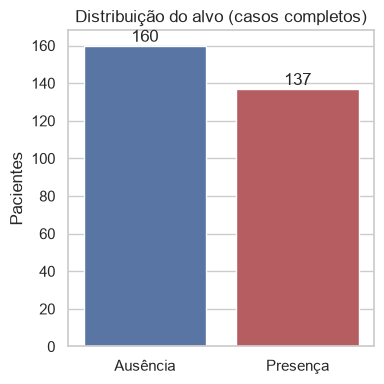

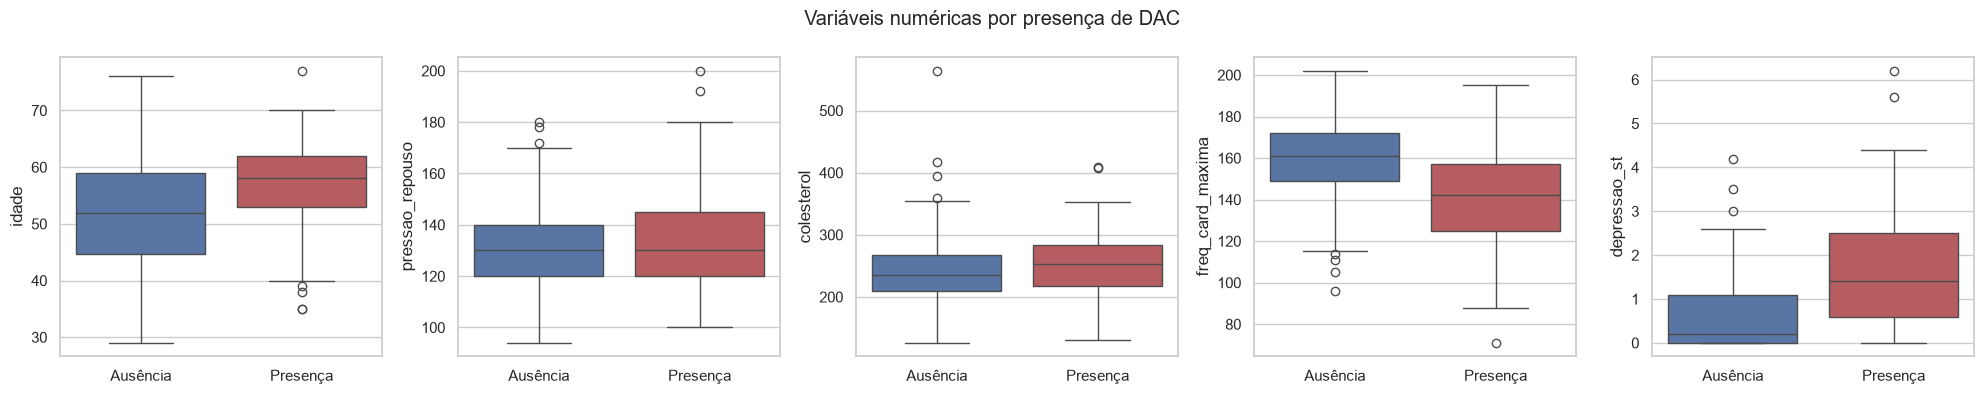

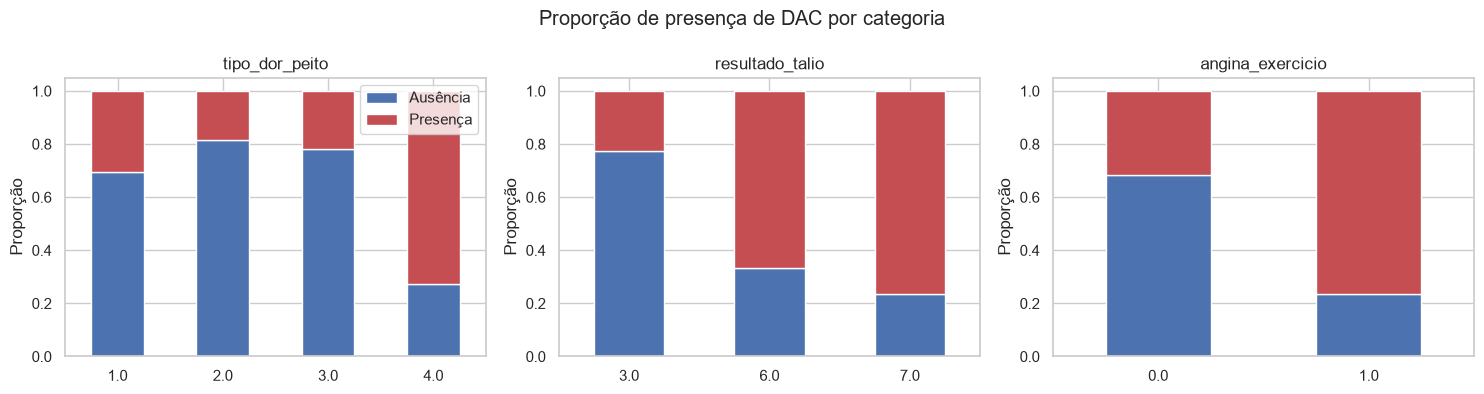

In [5]:
# EDA: distribuição do alvo, variáveis numéricas e categóricas por classe
numericas_eda = ["idade", "pressao_repouso", "colesterol", "freq_card_maxima", "depressao_st"]
cores = ["#4C72B0", "#C44E52"]

fig, ax = plt.subplots(figsize=(4, 4))
contagem = df_limpo["alvo"].value_counts().sort_index()
sns.barplot(x=["Ausência", "Presença"], y=contagem.values, hue=contagem.index, palette=cores, legend=False, ax=ax)
for i, v in enumerate(contagem.values): ax.text(i, v + 2, str(v), ha="center")
ax.set_title("Distribuição do alvo (casos completos)"); ax.set_ylabel("Pacientes")
plt.tight_layout(); plt.savefig("../figuras/distribuicao_alvo.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, numericas_eda):
    sns.boxplot(data=df_limpo, x="alvo", y=col, hue="alvo", palette=cores, legend=False, ax=ax)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Ausência", "Presença"]); ax.set_xlabel("")
plt.suptitle("Variáveis numéricas por presença de DAC"); plt.tight_layout()
plt.savefig("../figuras/boxplots_numericas.png", dpi=150); plt.show()

cat_chave = ["tipo_dor_peito", "resultado_talio", "angina_exercicio"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, cat_chave):
    t = pd.crosstab(df_limpo[col], df_limpo["alvo"], normalize="index"); t.columns = ["Ausência", "Presença"]
    t.plot(kind="bar", stacked=True, color=cores, ax=ax, legend=(col == cat_chave[0]))
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("Proporção"); ax.tick_params(axis="x", rotation=0)
plt.suptitle("Proporção de presença de DAC por categoria"); plt.tight_layout()
plt.savefig("../figuras/categoricas_vs_alvo.png", dpi=150); plt.show()

**Leitura da EDA:** (i) a base completa tem 297 pacientes, 46,1% com DAC; (ii) a prevalência difere muito por sexo (26,0% nas mulheres, n=96; 55,7% nos homens, n=201), o que condiciona qualquer comparação entre subgrupos (Seção 11); (iii) os 6 registros excluídos são 2% da base, 2 deles positivos (139 positivos no bruto contra 137 nos completos); (iv) pacientes com DAC têm, em mediana, frequência cardíaca máxima menor e depressão do segmento ST maior, e a categoria 4 de dor no peito (angina assintomática) concentra a maior proporção de casos positivos, o mesmo padrão já descrito na Parte 2. A exclusão dos 6 registros é avaliada empiricamente na Seção 9, em vez de apenas justificada por ser pequena.

## 3. Divisão treino/teste e definição dos cenários de atributos

A divisão é **a mesma da Parte 2** (80/20, estratificada pelo alvo, `random_state=42`), para manter a
continuidade entre as entregas. Ela é feita sobre os dados **brutos** (sem one-hot/padronização), porque
o pré-processamento agora faz parte do `Pipeline` (decisão D1).

In [6]:
NUMERICAS = ["idade", "pressao_repouso", "colesterol", "freq_card_maxima", "depressao_st", "num_vasos_fluoroscopia"]
CATEGORICAS = ["sexo", "tipo_dor_peito", "glicemia_jejum_alta", "ecg_repouso", "angina_exercicio",
               "inclinacao_st", "resultado_talio"]

X_bruto = df_limpo[NUMERICAS + CATEGORICAS]
y = df_limpo["alvo"]
X_tr, X_te, y_tr, y_te = train_test_split(X_bruto, y, test_size=0.2, stratify=y, random_state=SEMENTE)
print(f"Treino: {len(X_tr)} ({y_tr.mean():.1%} positivos) | Teste: {len(X_te)} ({y_te.mean():.1%} positivos)")

# Cenários de atributos (decisão D6)
CENARIOS = {
    "Completo (13 atributos)": NUMERICAS + CATEGORICAS,
    "Sem imagem/perfusão (11)": [c for c in NUMERICAS + CATEGORICAS if c not in ("num_vasos_fluoroscopia", "resultado_talio")],
    "Consulta básica (7)": ["idade", "sexo", "tipo_dor_peito", "pressao_repouso", "colesterol",
                           "glicemia_jejum_alta", "ecg_repouso"],
}
for nome, cols in CENARIOS.items():
    print(f"{nome}: {cols}")

Treino: 237 (46.0% positivos) | Teste: 60 (46.7% positivos)
Completo (13 atributos): ['idade', 'pressao_repouso', 'colesterol', 'freq_card_maxima', 'depressao_st', 'num_vasos_fluoroscopia', 'sexo', 'tipo_dor_peito', 'glicemia_jejum_alta', 'ecg_repouso', 'angina_exercicio', 'inclinacao_st', 'resultado_talio']
Sem imagem/perfusão (11): ['idade', 'pressao_repouso', 'colesterol', 'freq_card_maxima', 'depressao_st', 'sexo', 'tipo_dor_peito', 'glicemia_jejum_alta', 'ecg_repouso', 'angina_exercicio', 'inclinacao_st']
Consulta básica (7): ['idade', 'sexo', 'tipo_dor_peito', 'pressao_repouso', 'colesterol', 'glicemia_jejum_alta', 'ecg_repouso']


## 4. Funções do protocolo

O bloco abaixo define o `Pipeline` de cada modelo (pré-processamento + classificador), as grades de
hiperparâmetros, a regra de seleção (D3), a escolha do limiar (D4) e os intervalos de confiança.

In [7]:
# ---------- Pré-processamento dentro do Pipeline (D1) ----------
def montar_pre(num, cat, padronizar):
    etapa_num = [("imputador", SimpleImputer(strategy="median"))]
    if padronizar:                       # padronização só para o modelo linear
        etapa_num.append(("escalonador", StandardScaler()))
    blocos = []
    if num: blocos.append(("num", Pipeline(etapa_num), num))
    if cat: blocos.append(("cat", Pipeline([("imputador", SimpleImputer(strategy="most_frequent")),
                                            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat))
    return ColumnTransformer(blocos)

def montar_modelos(colunas):
    num = [c for c in NUMERICAS if c in colunas]
    cat = [c for c in CATEGORICAS if c in colunas]
    return {
        "Regressão Logística": (
            Pipeline([("pre", montar_pre(num, cat, True)),
                      ("modelo", LogisticRegression(max_iter=5000, random_state=SEMENTE))]),
            {"modelo__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}),
        "Random Forest": (
            Pipeline([("pre", montar_pre(num, cat, False)),
                      ("modelo", RandomForestClassifier(n_estimators=300, random_state=SEMENTE, n_jobs=1))]),
            {"modelo__max_depth": [3, 5, None], "modelo__min_samples_leaf": [1, 3, 5],
             "modelo__max_features": ["sqrt", 0.5]}),
        "XGBoost": (
            Pipeline([("pre", montar_pre(num, cat, False)),
                      ("modelo", XGBClassifier(eval_metric="logloss", random_state=SEMENTE, n_jobs=1))]),
            {"modelo__n_estimators": [100, 300], "modelo__max_depth": [2, 3, 4],
             "modelo__learning_rate": [0.03, 0.1], "modelo__subsample": [0.8, 1.0]}),
    }

ORDEM_SIMPLICIDADE = ["Regressão Logística", "Random Forest", "XGBoost"]
METRICAS_CV = {"roc_auc": "roc_auc", "sensibilidade": "recall", "especificidade": make_scorer(recall_score, pos_label=0),
               "f1": "f1", "acuracia": "accuracy", "brier": "neg_brier_score"}

# ---------- Regra de seleção definida a priori (D3) ----------
def selecionar_modelo(auc_por_modelo):
    medias = {n: np.mean(v) for n, v in auc_por_modelo.items()}
    melhor = max(medias, key=medias.get)
    ep = np.std(auc_por_modelo[melhor], ddof=1) / np.sqrt(len(auc_por_modelo[melhor]))
    elegiveis = [n for n in ORDEM_SIMPLICIDADE if medias[n] >= medias[melhor] - ep]
    return elegiveis[0], melhor, ep

# ---------- Limiar (D4) ----------
def metricas_em(y_real, proba, limiar):
    pred = (proba >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    return {"roc_auc": roc_auc_score(y_real, proba), "sensibilidade": tp / (tp + fn), "especificidade": tn / (tn + fp),
            "acuracia": (tp + tn) / len(y_real), "f1": f1_score(y_real, pred, zero_division=0),
            "brier": brier_score_loss(y_real, proba), "tn": tn, "fp": fp, "fn": fn, "tp": tp}

GRADE_LIMIARES = np.round(np.arange(0.05, 0.96, 0.01), 2)
def escolher_limiar(y_real, proba, alvo_sens=0.90):
    ok = [t for t in GRADE_LIMIARES if metricas_em(y_real, proba, t)["sensibilidade"] >= alvo_sens]
    return float(max(ok)) if ok else float(GRADE_LIMIARES.min())

# ---------- Intervalos de confiança ----------
def clopper_pearson(k, n, alfa=0.05):
    if n == 0: return (np.nan, np.nan)
    lo = 0.0 if k == 0 else stats.beta.ppf(alfa / 2, k, n - k + 1)
    hi = 1.0 if k == n else stats.beta.ppf(1 - alfa / 2, k + 1, n - k)
    return (lo, hi)

def ic_bootstrap(y_real, proba, limiar, n_boot=2000, semente=SEMENTE):
    # bootstrap estratificado por classe (mantém o nº de positivos/negativos do teste)
    rng = np.random.default_rng(semente)
    y_real = np.asarray(y_real); proba = np.asarray(proba)
    pos, neg = np.where(y_real == 1)[0], np.where(y_real == 0)[0]
    reg = {k: [] for k in ["roc_auc", "sensibilidade", "especificidade", "acuracia", "f1"]}
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        m = metricas_em(y_real[idx], proba[idx], limiar)
        for k in reg: reg[k].append(m[k])
    return {k: tuple(np.percentile(v, [2.5, 97.5])) for k, v in reg.items()}

In [8]:
# ---------- Protocolo completo para um cenário ----------
def executar_protocolo(nome_cenario, colunas, verbose=True):
    Xa, Xb = X_tr[colunas], X_te[colunas]
    modelos = montar_modelos(colunas)

    # (D3) validação cruzada ANINHADA no treino: o ajuste de hiperparâmetros acontece dentro de cada
    # partição externa, então a estimativa de desempenho não é otimista pelo ajuste.
    externo = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEMENTE)
    interno = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMENTE)
    cv_aninhado = {}
    for nome, (pipe, grade) in modelos.items():
        busca = GridSearchCV(pipe, grade, scoring="roc_auc", cv=interno, n_jobs=-1)
        r = cross_validate(busca, Xa, y_tr, cv=externo, scoring=METRICAS_CV, n_jobs=1)
        cv_aninhado[nome] = {m: r[f"test_{m}"] for m in METRICAS_CV}

    escolhido, melhor_bruto, ep = selecionar_modelo({n: v["roc_auc"] for n, v in cv_aninhado.items()})

    # (D2) ajuste final dos hiperparâmetros de cada modelo em TODO o treino (5 partições)
    final = {}
    for nome, (pipe, grade) in modelos.items():
        busca = GridSearchCV(pipe, grade, scoring="roc_auc", cv=StratifiedKFold(5, shuffle=True, random_state=SEMENTE),
                             n_jobs=-1).fit(Xa, y_tr)
        final[nome] = busca

    # (D4) limiar do modelo escolhido, por predições fora da amostra no treino
    est = final[escolhido].best_estimator_
    oof = cross_val_predict(clone(est), Xa, y_tr, cv=StratifiedKFold(10, shuffle=True, random_state=SEMENTE),
                            method="predict_proba")[:, 1]
    limiar = escolher_limiar(y_tr, oof, 0.90)

    # (D5) avaliação final única no teste
    proba_te = {n: final[n].best_estimator_.predict_proba(Xb)[:, 1] for n in modelos}
    p = proba_te[escolhido]
    res = {
        "cenario": nome_cenario, "colunas": colunas, "cv_aninhado": cv_aninhado, "escolhido": escolhido,
        "melhor_bruto": melhor_bruto, "ep": ep, "final": final, "oof": oof, "limiar": limiar,
        "proba_te": proba_te, "teste_05": metricas_em(y_te, p, 0.5), "teste_lim": metricas_em(y_te, p, limiar),
        "ic_05": ic_bootstrap(y_te, p, 0.5), "ic_lim": ic_bootstrap(y_te, p, limiar),
        "oof_lim": metricas_em(y_tr, oof, limiar),
    }
    if verbose:
        print(f"=== {nome_cenario} ===")
        for n in modelos:
            a = cv_aninhado[n]["roc_auc"]
            print(f"  CV aninhada ROC-AUC {n:20s}: {a.mean():.3f} ± {a.std(ddof=1):.3f}")
        print(f"  Melhor bruto: {melhor_bruto} | erro-padrão {ep:.3f} | ESCOLHIDO pela regra D3: {escolhido}")
        print(f"  Hiperparâmetros: {final[escolhido].best_params_}")
        print(f"  Limiar (sens. OOF ≥ 0,90): {limiar:.2f} | OOF -> sens {res['oof_lim']['sensibilidade']:.3f}, esp {res['oof_lim']['especificidade']:.3f}")
    return res

## 5. Execução do protocolo nos três cenários

*(A célula abaixo é a mais demorada do notebook: validação cruzada aninhada + busca em grade para cada
modelo e cada cenário.)*

In [9]:
import time
t0 = time.time()
R = {nome: executar_protocolo(nome, cols) for nome, cols in CENARIOS.items()}
print(f"\nTempo total: {(time.time() - t0)/60:.1f} min")

=== Completo (13 atributos) ===
  CV aninhada ROC-AUC Regressão Logística : 0.898 ± 0.055
  CV aninhada ROC-AUC Random Forest       : 0.888 ± 0.045
  CV aninhada ROC-AUC XGBoost             : 0.892 ± 0.056
  Melhor bruto: Regressão Logística | erro-padrão 0.017 | ESCOLHIDO pela regra D3: Regressão Logística
  Hiperparâmetros: {'modelo__C': 0.1}
  Limiar (sens. OOF ≥ 0,90): 0.26 | OOF -> sens 0.917, esp 0.594


=== Sem imagem/perfusão (11) ===
  CV aninhada ROC-AUC Regressão Logística : 0.860 ± 0.061
  CV aninhada ROC-AUC Random Forest       : 0.851 ± 0.058
  CV aninhada ROC-AUC XGBoost             : 0.853 ± 0.054
  Melhor bruto: Regressão Logística | erro-padrão 0.019 | ESCOLHIDO pela regra D3: Regressão Logística
  Hiperparâmetros: {'modelo__C': 0.1}
  Limiar (sens. OOF ≥ 0,90): 0.24 | OOF -> sens 0.908, esp 0.477


=== Consulta básica (7) ===
  CV aninhada ROC-AUC Regressão Logística : 0.828 ± 0.058
  CV aninhada ROC-AUC Random Forest       : 0.834 ± 0.058
  CV aninhada ROC-AUC XGBoost             : 0.818 ± 0.064
  Melhor bruto: Random Forest | erro-padrão 0.018 | ESCOLHIDO pela regra D3: Regressão Logística
  Hiperparâmetros: {'modelo__C': 0.3}
  Limiar (sens. OOF ≥ 0,90): 0.26 | OOF -> sens 0.908, esp 0.453

Tempo total: 10.2 min


**Leitura:** a regra D3 escolheu a **Regressão Logística nos três cenários**. No cenário completo, a ROC-AUC da validação cruzada aninhada foi 0,898 (LR), 0,892 (XGBoost) e 0,888 (Random Forest); a diferença entre os modelos (≤ 0,010) é bem menor que o desvio-padrão entre partições (≈ 0,05), ou seja, **os três são estatisticamente indistinguíveis** neste tamanho de amostra, e a regra de preferir o mais simples é o desempate apropriado. No cenário de consulta básica o Random Forest teve a maior média bruta (0,834 contra 0,828), mas dentro de 1 erro-padrão (0,018), portanto a regra manteve a LR. Ressalva: as partições da validação cruzada compartilham dados, então o erro-padrão calculado **subestima** a incerteza real (Varoquaux, 2018) – a conclusão prudente é a de empate técnico. Isso muda o que a Parte 2 sugeria (XGBoost por F1 no teste; LR por ROC-AUC no teste): agora a escolha vem de um critério fixado antes e calculado só com dados de treino.

### 5.1 Cenário completo: validação cruzada aninhada (dispersão entre partições)

In [10]:
P = R["Completo (13 atributos)"]
linhas = []
for nome, v in P["cv_aninhado"].items():
    linha = {"Modelo": nome}
    for m, rot in [("roc_auc", "ROC-AUC"), ("sensibilidade", "Sensib."), ("especificidade", "Espec."), ("f1", "F1"), ("acuracia", "Acurácia")]:
        linha[rot] = f"{v[m].mean():.3f} ± {v[m].std(ddof=1):.3f}"
    linha["Brier"] = f"{-v['brier'].mean():.3f} ± {v['brier'].std(ddof=1):.3f}"
    linhas.append(linha)
tabela_cv = pd.DataFrame(linhas).set_index("Modelo")
print("Média ± desvio-padrão entre as 10 partições externas (5 partições x 2 repetições), limiar 0,5, só treino:")
tabela_cv

Média ± desvio-padrão entre as 10 partições externas (5 partições x 2 repetições), limiar 0,5, só treino:


,ROC-AUC,Sensib.,Espec.,F1,Acurácia,Brier
Modelo,,,,,,
Regressão Logística,0.898 ± 0.055,0.783 ± 0.094,0.890 ± 0.074,0.818 ± 0.069,0.842 ± 0.059,0.129 ± 0.032
Random Forest,0.888 ± 0.045,0.765 ± 0.092,0.871 ± 0.075,0.797 ± 0.052,0.823 ± 0.043,0.140 ± 0.020
XGBoost,0.892 ± 0.056,0.779 ± 0.090,0.847 ± 0.083,0.795 ± 0.053,0.816 ± 0.046,0.134 ± 0.031


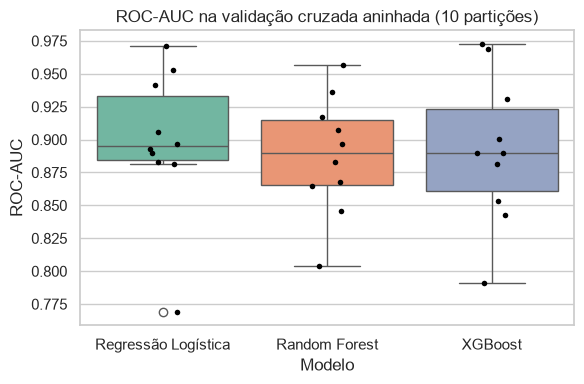

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
dados = pd.DataFrame({n: v["roc_auc"] for n, v in P["cv_aninhado"].items()}).melt(var_name="Modelo", value_name="ROC-AUC")
sns.boxplot(data=dados, x="Modelo", y="ROC-AUC", hue="Modelo", palette="Set2", legend=False, ax=ax)
sns.stripplot(data=dados, x="Modelo", y="ROC-AUC", color="black", size=4, ax=ax)
ax.set_title("ROC-AUC na validação cruzada aninhada (10 partições)")
plt.tight_layout(); plt.savefig("../figuras/cv_aninhada_auc.png", dpi=150); plt.show()

### 5.2 Hiperparâmetros finais de cada modelo (ajustados em todo o treino)

In [12]:
hp = pd.DataFrame({n: {k.replace("modelo__", ""): v for k, v in b.best_params_.items()} for n, b in P["final"].items()}).T
hp["ROC-AUC (CV interna, treino)"] = [round(b.best_score_, 3) for b in P["final"].values()]
hp

,C,max_depth,max_features,min_samples_leaf,learning_rate,n_estimators,subsample,"ROC-AUC (CV interna, treino)"
Regressão Logística,0.1,NaN,NaN,NaN,NaN,NaN,NaN,0.896
Random Forest,NaN,None,sqrt,3,NaN,NaN,NaN,0.902
XGBoost,NaN,2.0,NaN,NaN,0.1,100.0,0.8,0.893


### 5.3 Escolha do limiar de decisão (apenas treino)

O limiar é o **maior** valor que mantém sensibilidade OOF ≥ 0,90 (decisão D4): em triagem, falso negativo
é o erro mais grave, e escolher o maior limiar possível dentro dessa restrição poupa especificidade.

In [13]:
oof, lim = P["oof"], P["limiar"]
tabela_lim = pd.DataFrame([{"limiar": t, **{k: round(v, 3) for k, v in metricas_em(y_tr, oof, t).items() if k in ("sensibilidade", "especificidade", "f1")}}
                           for t in [0.20, 0.30, 0.40, 0.50, 0.60, lim]]).drop_duplicates("limiar").sort_values("limiar").set_index("limiar")
print(f"Modelo escolhido: {P['escolhido']} | limiar selecionado = {lim:.2f}")
tabela_lim

Modelo escolhido: Regressão Logística | limiar selecionado = 0.26


,sensibilidade,especificidade,f1
limiar,,,
0.20,0.954,0.492,0.748
0.26,0.917,0.594,0.766
0.30,0.881,0.672,0.777
0.40,0.835,0.797,0.805
0.50,0.780,0.875,0.810
0.60,0.661,0.930,0.758


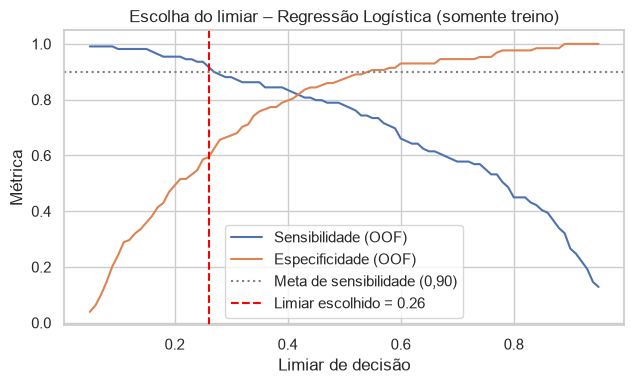

In [14]:
ts = GRADE_LIMIARES
sens = [metricas_em(y_tr, oof, t)["sensibilidade"] for t in ts]
esp = [metricas_em(y_tr, oof, t)["especificidade"] for t in ts]
plt.figure(figsize=(6.5, 4))
plt.plot(ts, sens, label="Sensibilidade (OOF)"); plt.plot(ts, esp, label="Especificidade (OOF)")
plt.axhline(0.90, color="gray", ls=":", label="Meta de sensibilidade (0,90)")
plt.axvline(lim, color="red", ls="--", label=f"Limiar escolhido = {lim:.2f}")
plt.xlabel("Limiar de decisão"); plt.ylabel("Métrica"); plt.title(f"Escolha do limiar – {P['escolhido']} (somente treino)")
plt.legend(); plt.tight_layout(); plt.savefig("../figuras/limiar.png", dpi=150); plt.show()

## 6. Avaliação final no conjunto de teste (uso único, decisão D5)

Intervalos de 95%: *bootstrap* estratificado (2000 reamostragens) para todas as métricas e
Clopper-Pearson exato para sensibilidade e especificidade (proporções simples).

In [15]:
def linha_teste(r, rotulo_lim):
    m = r["teste_lim"] if rotulo_lim else r["teste_05"]
    ic = r["ic_lim"] if rotulo_lim else r["ic_05"]
    ncp = m["tp"] + m["fn"]; nn = m["tn"] + m["fp"]
    return {"Cenário": r["cenario"], "Modelo": r["escolhido"],
            "Limiar": f"{r['limiar']:.2f}" if rotulo_lim else "0,50",
            "ROC-AUC": f"{m['roc_auc']:.3f} [{ic['roc_auc'][0]:.3f}; {ic['roc_auc'][1]:.3f}]",
            "Sensib.": f"{m['sensibilidade']:.3f} [{clopper_pearson(m['tp'], ncp)[0]:.3f}; {clopper_pearson(m['tp'], ncp)[1]:.3f}]",
            "Espec.": f"{m['especificidade']:.3f} [{clopper_pearson(m['tn'], nn)[0]:.3f}; {clopper_pearson(m['tn'], nn)[1]:.3f}]",
            "F1": f"{m['f1']:.3f} [{ic['f1'][0]:.3f}; {ic['f1'][1]:.3f}]",
            "FN": int(m["fn"]), "FP": int(m["fp"])}

print(f"Teste: n = {len(y_te)} ({int(y_te.sum())} positivos, {int((1-y_te).sum())} negativos). Modelo escolhido a priori (D3).")
tab_teste_05 = pd.DataFrame([linha_teste(P, False)]).set_index("Cenário")
tab_teste_lim = pd.DataFrame([linha_teste(P, True)]).set_index("Cenário")
print("\nLimiar padrão 0,50:"); display(tab_teste_05)
print("Limiar escolhido no treino (sensibilidade-alvo 0,90):"); display(tab_teste_lim)

Teste: n = 60 (28 positivos, 32 negativos). Modelo escolhido a priori (D3).

Limiar padrão 0,50:


,Modelo,Limiar,ROC-AUC,Sensib.,Espec.,F1,FN,FP
Cenário,,,,,,,,
Completo (13 atributos),Regressão Logística,"0,50",0.952 [0.894; 0.993],0.821 [0.631; 0.939],0.906 [0.750; 0.980],0.852 [0.745; 0.945],5,3


Limiar escolhido no treino (sensibilidade-alvo 0,90):


,Modelo,Limiar,ROC-AUC,Sensib.,Espec.,F1,FN,FP
Cenário,,,,,,,,
Completo (13 atributos),Regressão Logística,0.26,0.952 [0.894; 0.993],0.964 [0.817; 0.999],0.781 [0.600; 0.907],0.871 [0.800; 0.949],1,7


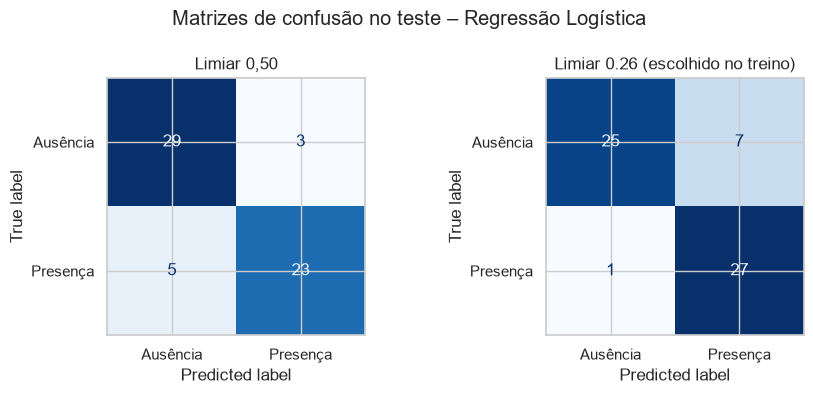

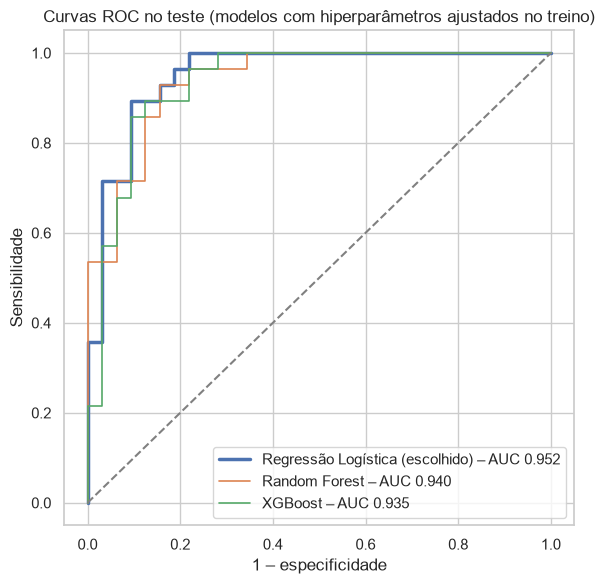

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (rot, lm) in zip(axes, [("Limiar 0,50", 0.5), (f"Limiar {P['limiar']:.2f} (escolhido no treino)", P["limiar"])]):
    pred = (P["proba_te"][P["escolhido"]] >= lm).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred, labels=[0, 1]), display_labels=["Ausência", "Presença"]).plot(
        cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(rot)
plt.suptitle(f"Matrizes de confusão no teste – {P['escolhido']}"); plt.tight_layout()
plt.savefig("../figuras/matrizes_confusao_teste.png", dpi=150); plt.show()

plt.figure(figsize=(6, 6))
for n, p in P["proba_te"].items():
    fpr, tpr, _ = roc_curve(y_te, p)
    plt.plot(fpr, tpr, lw=2.5 if n == P["escolhido"] else 1.2,
             label=f"{n}{' (escolhido)' if n == P['escolhido'] else ''} – AUC {roc_auc_score(y_te, p):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray"); plt.xlabel("1 – especificidade"); plt.ylabel("Sensibilidade")
plt.title("Curvas ROC no teste (modelos com hiperparâmetros ajustados no treino)"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig("../figuras/curvas_roc_teste.png", dpi=150); plt.show()

### 6.1 Os três modelos no teste (apenas informativo)

O modelo "oficial" foi escolhido **antes** pela regra D3. A tabela abaixo mostra os três com
hiperparâmetros ajustados no treino, para transparência – **não** deve ser usada para trocar o modelo.

In [17]:
linhas = []
for n, p in P["proba_te"].items():
    m = metricas_em(y_te, p, 0.5)
    linhas.append({"Modelo": n + (" (escolhido)" if n == P["escolhido"] else ""), "ROC-AUC": round(m["roc_auc"], 3),
                   "Sensib.": round(m["sensibilidade"], 3), "Espec.": round(m["especificidade"], 3),
                   "F1": round(m["f1"], 3), "Acurácia": round(m["acuracia"], 3), "FN": int(m["fn"]), "FP": int(m["fp"])})
pd.DataFrame(linhas).set_index("Modelo")

,ROC-AUC,Sensib.,Espec.,F1,Acurácia,FN,FP
Modelo,,,,,,,
Regressão Logística (escolhido),0.952,0.821,0.906,0.852,0.867,5,3
Random Forest,0.940,0.750,0.875,0.792,0.817,7,4
XGBoost,0.935,0.821,0.906,0.852,0.867,5,3


**Leitura:** com limiar 0,50, o modelo escolhido obteve ROC-AUC 0,952 (IC 95%: 0,894–0,993), sensibilidade 0,821 (23 de 28; IC 0,631–0,939) e especificidade 0,906 (29 de 32; IC 0,750–0,980), com 5 falsos negativos. Com o limiar escolhido **só com dados de treino** (0,26), a sensibilidade sobe para 0,964 (27 de 28; IC 0,817–0,999) e a especificidade cai para 0,781 (25 de 32; IC 0,600–0,907): **1 falso negativo e 7 falsos positivos**. Os intervalos são largos – com 60 pacientes, a incerteza é grande –, e o resultado no teste foi mais favorável que o estimado no treino (sensibilidade OOF 0,917 e especificidade OOF 0,594 no limiar 0,26), o que a Seção 7 explica. A tabela 6.1 mostra que Random Forest e XGBoost também têm desempenho semelhante, sem que isso altere o modelo escolhido a priori.

## 7. Quão estável é o resultado do teste? Repetição de 200 divisões treino/teste

Com apenas 60 pacientes no teste, o número obtido depende da divisão sorteada. Aqui, o **mesmo pipeline
e os mesmos hiperparâmetros** do modelo escolhido são reajustados em 200 divisões estratificadas
diferentes (sem novo ajuste de hiperparâmetros – variabilidade da divisão, não da busca).

In [18]:
est_base = P["final"][P["escolhido"]].best_estimator_
cols_c = P["colunas"]
reg = []
for i in range(200):
    a, b, ya, yb = train_test_split(X_bruto[cols_c], y, test_size=0.2, stratify=y, random_state=1000 + i)
    m = clone(est_base).fit(a, ya)
    pr = m.predict_proba(b)[:, 1]
    r05, rl = metricas_em(yb, pr, 0.5), metricas_em(yb, pr, P["limiar"])
    reg.append({"roc_auc": r05["roc_auc"], "sens_05": r05["sensibilidade"], "esp_05": r05["especificidade"],
                "sens_lim": rl["sensibilidade"], "esp_lim": rl["especificidade"]})
rob = pd.DataFrame(reg)
resumo_rob = rob.describe(percentiles=[0.025, 0.5, 0.975]).T[["mean", "std", "2.5%", "50%", "97.5%"]].round(3)
resumo_rob.index = ["ROC-AUC", "Sensib. (0,50)", "Espec. (0,50)", f"Sensib. ({P['limiar']:.2f})", f"Espec. ({P['limiar']:.2f})"]
resumo_rob

,mean,std,2.5%,50%,97.5%
ROC-AUC,0.909,0.033,0.845,0.912,0.971
"Sensib. (0,50)",0.790,0.070,0.643,0.786,0.929
"Espec. (0,50)",0.903,0.054,0.781,0.906,1.000
Sensib. (0.26),0.925,0.049,0.821,0.929,1.000
Espec. (0.26),0.634,0.082,0.469,0.625,0.782


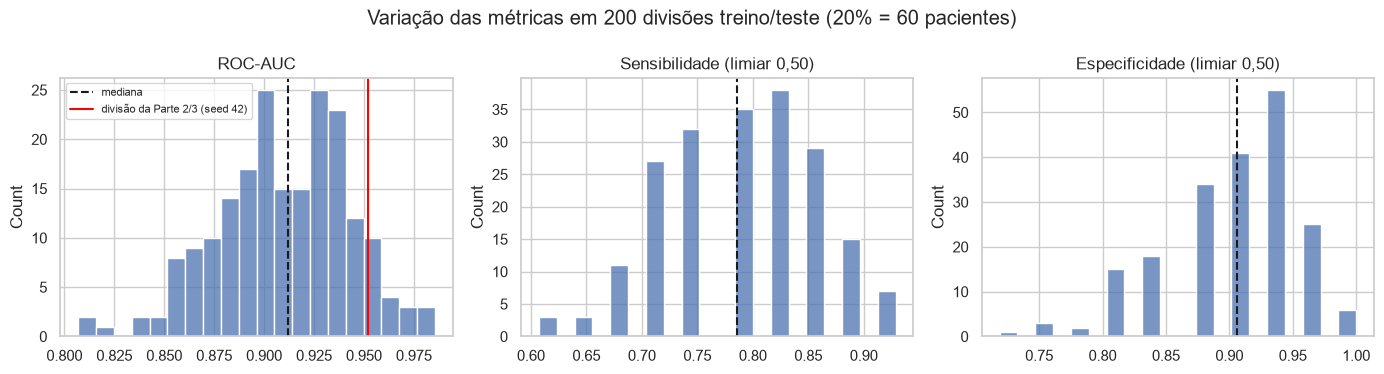

A divisão usada neste notebook (seed 42) tem ROC-AUC 0.952, acima de 92% das 200 divisões alternativas.


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (col, rot) in zip(axes, [("roc_auc", "ROC-AUC"), ("sens_05", "Sensibilidade (limiar 0,50)"), ("esp_05", "Especificidade (limiar 0,50)")]):
    sns.histplot(rob[col], bins=20, ax=ax, color="#4C72B0")
    ax.axvline(rob[col].median(), color="k", ls="--", label="mediana")
    ax.set_title(rot); ax.set_xlabel("")
axes[0].axvline(P["teste_05"]["roc_auc"], color="red", label="divisão da Parte 2/3 (seed 42)")
axes[0].legend(fontsize=8)
plt.suptitle("Variação das métricas em 200 divisões treino/teste (20% = 60 pacientes)")
plt.tight_layout(); plt.savefig("../figuras/robustez_divisoes.png", dpi=150); plt.show()
pct = (rob["roc_auc"] < P["teste_05"]["roc_auc"]).mean() * 100
print(f"A divisão usada neste notebook (seed 42) tem ROC-AUC {P['teste_05']['roc_auc']:.3f}, acima de {pct:.0f}% das 200 divisões alternativas.")

**Leitura:** nas 200 divisões alternativas a ROC-AUC média foi 0,909 (desvio-padrão 0,033; 95% das divisões entre 0,845 e 0,971) e a sensibilidade em 0,50 variou de 0,643 a 0,929. A divisão usada no teste principal (seed 42) deu AUC 0,952, **acima de 92% das alternativas** – ou seja, é uma divisão favorável. O melhor retrato do desempenho esperado é, portanto, a faixa de **ROC-AUC ≈ 0,90–0,91**, consistente com a validação cruzada aninhada (0,898) e com a validação cruzada repetida da Seção 9 (0,911). No limiar 0,26, a sensibilidade média foi 0,925 (0,821–1,000) e a especificidade média 0,634 (0,469–0,782), bem abaixo dos 0,781 observados no teste principal.

## 8. Cenários de atributos disponíveis na triagem (decisão D6)

Se fluoroscopia e teste de tálio **não** estão disponíveis no momento da triagem, o modelo "completo"
não seria utilizável nesse ponto do fluxo. Comparam-se, com o mesmo protocolo, os três cenários.

In [20]:
linhas = []
for nome, r in R.items():
    a = r["cv_aninhado"][r["escolhido"]]["roc_auc"]
    m5, ml = r["teste_05"], r["teste_lim"]
    linhas.append({"Cenário": nome, "Modelo escolhido (D3)": r["escolhido"],
                   "CV aninhada ROC-AUC (treino)": f"{a.mean():.3f} ± {a.std(ddof=1):.3f}",
                   "Teste ROC-AUC [IC95%]": f"{m5['roc_auc']:.3f} [{r['ic_05']['roc_auc'][0]:.3f}; {r['ic_05']['roc_auc'][1]:.3f}]",
                   "Limiar": f"{r['limiar']:.2f}",
                   "Sensib. no limiar": f"{ml['sensibilidade']:.3f}", "Espec. no limiar": f"{ml['especificidade']:.3f}",
                   "FN": int(ml["fn"]), "FP": int(ml["fp"])})
tabela_cenarios = pd.DataFrame(linhas).set_index("Cenário")
tabela_cenarios

,Modelo escolhido (D3),CV aninhada ROC-AUC (treino),Teste ROC-AUC [IC95%],Limiar,Sensib. no limiar,Espec. no limiar,FN,FP
Cenário,,,,,,,,
Completo (13 atributos),Regressão Logística,0.898 ± 0.055,0.952 [0.894; 0.993],0.26,0.964,0.781,1,7
Sem imagem/perfusão (11),Regressão Logística,0.860 ± 0.061,0.917 [0.840; 0.975],0.24,0.964,0.656,1,11
Consulta básica (7),Regressão Logística,0.828 ± 0.058,0.845 [0.734; 0.935],0.26,0.893,0.625,3,12


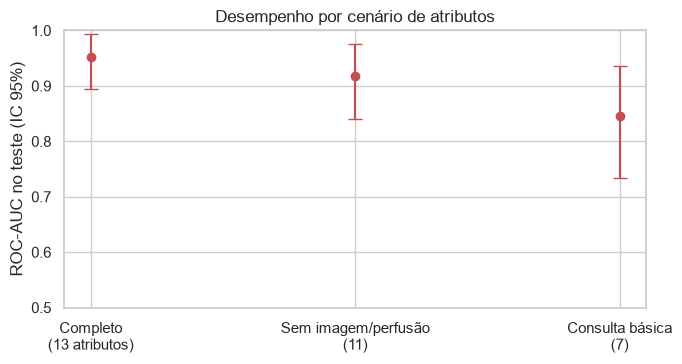

In [21]:
fig, ax = plt.subplots(figsize=(7, 3.8))
nomes = list(R.keys())
auc = [R[n]["teste_05"]["roc_auc"] for n in nomes]
lo = [R[n]["teste_05"]["roc_auc"] - R[n]["ic_05"]["roc_auc"][0] for n in nomes]
hi = [R[n]["ic_05"]["roc_auc"][1] - R[n]["teste_05"]["roc_auc"] for n in nomes]
ax.errorbar(range(3), auc, yerr=[lo, hi], fmt="o", capsize=5, color="#C44E52")
ax.set_xticks(range(3)); ax.set_xticklabels([n.replace(" (", "\n(") for n in nomes]); ax.set_ylim(0.5, 1.0)
ax.set_ylabel("ROC-AUC no teste (IC 95%)"); ax.set_title("Desempenho por cenário de atributos")
plt.tight_layout(); plt.savefig("../figuras/cenarios.png", dpi=150); plt.show()

**Leitura:** retirar fluoroscopia e teste de tálio reduz a ROC-AUC no teste de 0,952 para 0,917, e limitar o modelo às variáveis de consulta básica (idade, sexo, tipo de dor, pressão, colesterol, glicemia, ECG de repouso) a reduz para 0,845 (IC 0,734–0,935); na validação cruzada aninhada a queda é de 0,898 para 0,860 e 0,828. Os ICs se sobrepõem, mas a tendência é consistente nas duas avaliações. Para manter sensibilidade ≥ 0,89 nos cenários mais restritos, a especificidade no teste cai para 0,656 e 0,625 (11 e 12 falsos positivos em 32 negativos). Interpretação: o modelo ainda discrimina acima do acaso sem os exames especializados, mas **o desempenho do cenário completo não pode ser transferido para o momento da triagem**; um modelo de consulta básica geraria muitos encaminhamentos desnecessários para manter a sensibilidade alta. Premissa já registrada: a divisão dos atributos por momento clínico é uma inferência própria, não validada por cardiologista.

## 9. Consequência da exclusão de registros incompletos (análise de sensibilidade)

Os 6 registros com valor ausente foram excluídos. Para avaliar o efeito dessa decisão, o mesmo modelo
(com os hiperparâmetros finais) é avaliado por validação cruzada repetida (5×5) em (a) casos completos
e (b) **todos os 303 registros**, com imputação (mediana/moda) feita **dentro** de cada partição.

In [22]:
cols_c = P["colunas"]
est_cmp = P["final"][P["escolhido"]].best_estimator_
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEMENTE)

X_todos, y_todos = df[cols_c], df["alvo"]
X_comp, y_comp = df_limpo[cols_c], df_limpo["alvo"]
r_comp = cross_validate(clone(est_cmp), X_comp, y_comp, cv=cv_rep, scoring=METRICAS_CV, n_jobs=-1)
r_todos = cross_validate(clone(est_cmp), X_todos, y_todos, cv=cv_rep, scoring=METRICAS_CV, n_jobs=-1)
sens_exc = pd.DataFrame({
    "Casos completos (n=297)": {m: f"{r_comp['test_'+m].mean():.3f} ± {r_comp['test_'+m].std(ddof=1):.3f}" for m in ["roc_auc", "sensibilidade", "especificidade", "f1"]},
    "Todos com imputação (n=303)": {m: f"{r_todos['test_'+m].mean():.3f} ± {r_todos['test_'+m].std(ddof=1):.3f}" for m in ["roc_auc", "sensibilidade", "especificidade", "f1"]},
})
sens_exc

,Casos completos (n=297),Todos com imputação (n=303)
roc_auc,0.911 ± 0.044,0.916 ± 0.034
sensibilidade,0.785 ± 0.090,0.791 ± 0.082
especificidade,0.904 ± 0.053,0.909 ± 0.055
f1,0.826 ± 0.063,0.832 ± 0.060


**Leitura:** a validação cruzada repetida deu ROC-AUC 0,911 ± 0,044 nos 297 casos completos e 0,916 ± 0,034 nos 303 registros com imputação feita dentro de cada partição; sensibilidade e especificidade também praticamente não mudam (diferenças ≤ 0,006, muito menores que o desvio-padrão). A exclusão dos 6 registros (2,0% da base, 2 positivos) **não alterou de forma apreciável as conclusões**, o que sustenta a decisão de usar casos completos; a consequência registrada é a perda de 6 pacientes de uma base já pequena.

## 10. Análise dos erros (falsos negativos e falsos positivos no teste)

No contexto de triagem, o falso negativo (paciente com DAC classificado como sem DAC) é o erro mais grave.
Abaixo, os pacientes mal classificados no limiar escolhido, e os pacientes que **todos** os modelos erram.

In [23]:
p_esc = P["proba_te"][P["escolhido"]]
teste = X_te[P["colunas"]].copy()
teste["alvo_real"] = y_te.values
teste["prob_modelo"] = p_esc.round(3)
teste["pred_limiar"] = (p_esc >= P["limiar"]).astype(int)
fn = teste[(teste.alvo_real == 1) & (teste.pred_limiar == 0)]
fp = teste[(teste.alvo_real == 0) & (teste.pred_limiar == 1)]
print(f"Falsos negativos no limiar {P['limiar']:.2f}: {len(fn)} | falsos positivos: {len(fp)}")
print("\nFalsos negativos:"); display(fn)
print("Falsos positivos:"); display(fp)

erram_todos = np.ones(len(y_te), bool)
for n, p in P["proba_te"].items():
    erram_todos &= ((p >= 0.5).astype(int) != y_te.values)
print(f"\nPacientes do teste classificados erradamente (limiar 0,50) pelos TRÊS modelos ao mesmo tempo: {erram_todos.sum()}")
if erram_todos.sum():
    display(X_te[P["colunas"]][erram_todos].assign(alvo_real=y_te.values[erram_todos]))

Falsos negativos no limiar 0.26: 1 | falsos positivos: 7

Falsos negativos:


,idade,pressao_repouso,colesterol,freq_card_maxima,depressao_st,num_vasos_fluoroscopia,sexo,tipo_dor_peito,glicemia_jejum_alta,ecg_repouso,angina_exercicio,inclinacao_st,resultado_talio,alvo_real,prob_modelo,pred_limiar
211,52.0,112.0,230.0,160.0,0.0,1.0,1.0,4.0,0.0,0.0,0.0,1.0,3.0,1,0.252,0


Falsos positivos:


,idade,pressao_repouso,colesterol,freq_card_maxima,depressao_st,num_vasos_fluoroscopia,sexo,tipo_dor_peito,glicemia_jejum_alta,ecg_repouso,angina_exercicio,inclinacao_st,resultado_talio,alvo_real,prob_modelo,pred_limiar
89,66.0,120.0,302.0,151.0,0.4,0.0,1.0,4.0,0.0,2.0,0.0,2.0,3.0,0,0.417,1
101,57.0,128.0,303.0,159.0,0.0,1.0,0.0,4.0,0.0,2.0,0.0,1.0,3.0,0,0.279,1
67,54.0,150.0,232.0,165.0,1.6,0.0,1.0,3.0,0.0,2.0,0.0,1.0,7.0,0,0.401,1
33,59.0,135.0,234.0,161.0,0.5,0.0,1.0,4.0,0.0,0.0,0.0,2.0,7.0,0,0.571,1
271,64.0,170.0,227.0,155.0,0.6,0.0,1.0,1.0,0.0,2.0,0.0,2.0,7.0,0,0.600,1
162,58.0,100.0,248.0,122.0,1.0,0.0,0.0,4.0,0.0,2.0,0.0,2.0,3.0,0,0.307,1
181,59.0,178.0,270.0,145.0,4.2,0.0,1.0,1.0,0.0,2.0,0.0,3.0,7.0,0,0.843,1



Pacientes do teste classificados erradamente (limiar 0,50) pelos TRÊS modelos ao mesmo tempo: 3


,idade,pressao_repouso,colesterol,freq_card_maxima,depressao_st,num_vasos_fluoroscopia,sexo,tipo_dor_peito,glicemia_jejum_alta,ecg_repouso,angina_exercicio,inclinacao_st,resultado_talio,alvo_real
66,60.0,140.0,185.0,155.0,3.0,0.0,1.0,3.0,0.0,2.0,0.0,2.0,3.0,1
33,59.0,135.0,234.0,161.0,0.5,0.0,1.0,4.0,0.0,0.0,0.0,2.0,7.0,0
181,59.0,178.0,270.0,145.0,4.2,0.0,1.0,1.0,0.0,2.0,0.0,3.0,7.0,0


**Leitura:** no limiar 0,26 há **um único falso negativo** (paciente de 52 anos, tipo de dor 4, 1 vaso na fluoroscopia, tálio normal, sem angina de esforço e sem depressão de ST; probabilidade 0,252, apenas 0,008 abaixo do limiar) – um perfil com poucos sinais isquêmicos. Entre os 7 falsos positivos, 4 têm defeito reversível no tálio (valor 7), achado típico de isquemia; uma hipótese (não testada aqui) é que haja isquemia funcional sem estenose visível na angiografia, o que tornaria parte desses "erros" clinicamente menos graves do que parecem. Três pacientes do teste são classificados erradamente (limiar 0,50) pelos três modelos ao mesmo tempo – um positivo sem vasos acometidos na fluoroscopia e com tálio normal (60 anos, ST 3,0) e dois negativos com achados alterados – o que indica casos intrinsecamente difíceis ou com ruído de rótulo, e não uma falha específica de um algoritmo.

## 11. Equidade por sexo (com intervalos de confiança)

Duas visões: (a) apenas o teste (n pequeno) e (b) predições **fora da amostra (OOF)** em todos os 297
casos completos por validação cruzada de 10 partições, que dão mais pacientes por subgrupo.
*(Análise exploratória: os hiperparâmetros vieram do treino, portanto (b) não é uma avaliação final.)*

In [24]:
def tabela_sexo(y_real, proba, sexo, limiar, titulo):
    linhas = []
    for g, rot in [(0, "Feminino"), (1, "Masculino")]:
        mk = np.asarray(sexo) == g
        m = metricas_em(np.asarray(y_real)[mk], np.asarray(proba)[mk], limiar)
        npos, nneg = m["tp"] + m["fn"], m["tn"] + m["fp"]
        s, e = clopper_pearson(m["tp"], npos), clopper_pearson(m["tn"], nneg)
        linhas.append({"Grupo": rot, "n": int(mk.sum()), "positivos": int(npos),
                       "Sensib. [IC95%]": f"{m['sensibilidade']:.3f} [{s[0]:.2f}; {s[1]:.2f}]",
                       "Espec. [IC95%]": f"{m['especificidade']:.3f} [{e[0]:.2f}; {e[1]:.2f}]",
                       "FN": int(m["fn"]), "FP": int(m["fp"])})
    print(titulo); return pd.DataFrame(linhas).set_index("Grupo")

display(tabela_sexo(y_te, p_esc, X_te["sexo"], P["limiar"], f"(a) Teste (n=60), limiar {P['limiar']:.2f}"))

oof_todos = cross_val_predict(clone(est_cmp), X_comp, y_comp, cv=StratifiedKFold(10, shuffle=True, random_state=SEMENTE),
                              method="predict_proba")[:, 1]
display(tabela_sexo(y_comp, oof_todos, X_comp["sexo"], P["limiar"], f"(b) OOF em 297 casos, limiar {P['limiar']:.2f}"))

(a) Teste (n=60), limiar 0.26


,n,positivos,Sensib. [IC95%],Espec. [IC95%],FN,FP
Grupo,,,,,,
Feminino,19,3,1.000 [0.29; 1.00],0.875 [0.62; 0.98],0,2
Masculino,41,25,0.960 [0.80; 1.00],0.688 [0.41; 0.89],1,5


(b) OOF em 297 casos, limiar 0.26


,n,positivos,Sensib. [IC95%],Espec. [IC95%],FN,FP
Grupo,,,,,,
Feminino,96,25,0.840 [0.64; 0.95],0.775 [0.66; 0.87],4,16
Masculino,201,112,0.955 [0.90; 0.99],0.517 [0.41; 0.62],5,43


**Leitura:** no teste, o subgrupo feminino tem apenas 3 casos positivos, então a sensibilidade de 100% tem IC de 0,29 a 1,00 – **não permite concluir nada**, e a impressão favorável às mulheres da Parte 2 não se sustenta. Com as predições fora da amostra em 297 pacientes, aparece um padrão relevante: no limiar único de 0,26 a **sensibilidade é menor nas mulheres** (0,840; IC 0,64–0,95; 4 falsos negativos em 25) que nos homens (0,955; IC 0,90–0,99; 5 em 112) – diferença no limite da significância (teste exato de Fisher, p ≈ 0,06) – e a **especificidade é muito menor nos homens** (0,517 contra 0,775; taxa de falso positivo 48% contra 29%, p ≈ 0,001). Parte disso decorre da prevalência (26% nas mulheres, 56% nos homens). Análise exploratória e *post hoc*, sem correção para múltiplas comparações; ainda assim, o recado é que **um limiar único produz perfis de erro diferentes por sexo**, e que um uso real exigiria monitoramento por subgrupo e, possivelmente, limiares ou calibração específicos.

## 12. Calibração das probabilidades

Um modelo de apoio à triagem só é útil se a probabilidade que ele devolve for razoavelmente confiável.
Avalia-se pelo escore de Brier e pela curva de confiabilidade (predições OOF no treino, 5 faixas).

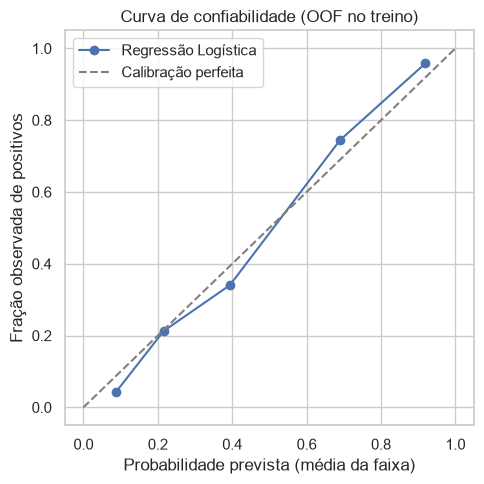

Brier OOF (treino): 0.131 | Brier no teste: 0.094 | referência (prever sempre a prevalência): 0.248


In [25]:
frac, media = calibration_curve(y_tr, P["oof"], n_bins=5, strategy="quantile")
plt.figure(figsize=(5, 5))
plt.plot(media, frac, "o-", label=P["escolhido"]); plt.plot([0, 1], [0, 1], "--", color="gray", label="Calibração perfeita")
plt.xlabel("Probabilidade prevista (média da faixa)"); plt.ylabel("Fração observada de positivos")
plt.title("Curva de confiabilidade (OOF no treino)"); plt.legend(); plt.tight_layout()
plt.savefig("../figuras/calibracao.png", dpi=150); plt.show()
print(f"Brier OOF (treino): {brier_score_loss(y_tr, P['oof']):.3f} | Brier no teste: {P['teste_05']['brier']:.3f} "
      f"| referência (prever sempre a prevalência): {y_tr.mean()*(1-y_tr.mean()):.3f}")

**Leitura:** o escore de Brier foi 0,131 nas predições fora da amostra do treino e 0,094 no teste, contra 0,248 de um modelo que sempre prevê a prevalência; a curva de confiabilidade segue próxima da diagonal, com leve subestimação nas pontas (faixa de ~0,09 prevista corresponde a ~4% observados; faixa de ~0,92 a ~96%). A calibração é razoável para uma base pequena, mas com 237 pacientes e 5 faixas a curva é ruidosa; **não** deve ser interpretada como calibração demonstrada para outra população.

## 13. Explicabilidade (cenário completo)

Duas técnicas complementares: **SHAP** (contribuição de cada atributo à predição) e **importância por
permutação** (queda de ROC-AUC no teste ao embaralhar cada atributo original). **Atenção:** concordância
com o conhecimento clínico torna o modelo *plausível*, mas **não** demonstra confiabilidade clínica –
isso exigiria validação externa e prospectiva.

Background dataset has 237 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=237 when initializing the masker.


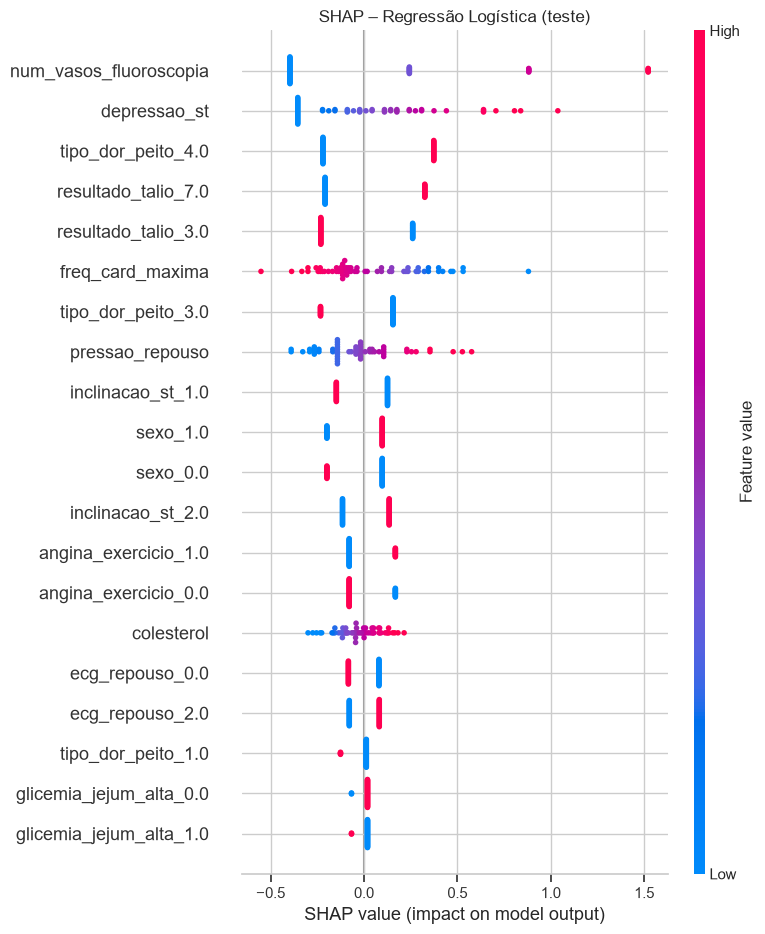

Ordem de importância SHAP (|valor| médio):
  num_vasos_fluoroscopia              0.532
  depressao_st                        0.304
  tipo_dor_peito_4.0                  0.286
  resultado_talio_7.0                 0.247
  resultado_talio_3.0                 0.242
  freq_card_maxima                    0.221
  tipo_dor_peito_3.0                  0.176
  pressao_repouso                     0.162
  inclinacao_st_1.0                   0.135
  sexo_1.0                            0.130


In [26]:
est = P["final"][P["escolhido"]].best_estimator_
pre, clf = est.named_steps["pre"], est.named_steps["modelo"]
nomes_f = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
Xtr_t, Xte_t = pre.transform(X_tr[P["colunas"]]), pre.transform(X_te[P["colunas"]])

if P["escolhido"] == "Regressão Logística":
    expl = shap.LinearExplainer(clf, Xtr_t)
else:
    expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t)
if isinstance(sv, list): sv = sv[1]
if getattr(sv, "ndim", 2) == 3: sv = sv[:, :, 1]

plt.figure()
shap.summary_plot(sv, Xte_t, feature_names=nomes_f, show=False)
plt.title(f"SHAP – {P['escolhido']} (teste)"); plt.tight_layout()
plt.savefig("../figuras/shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()

ordem = np.argsort(-np.abs(sv).mean(0))
print("Ordem de importância SHAP (|valor| médio):")
for i in ordem[:10]: print(f"  {nomes_f[i]:35s} {np.abs(sv).mean(0)[i]:.3f}")

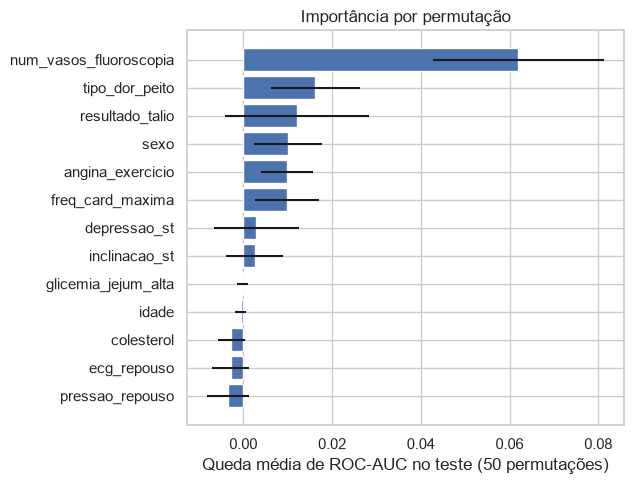

,atributo,queda_auc,dp
0,num_vasos_fluoroscopia,0.062,0.019
1,tipo_dor_peito,0.016,0.010
2,resultado_talio,0.012,0.016
3,sexo,0.010,0.008
4,angina_exercicio,0.010,0.006
5,freq_card_maxima,0.010,0.007
6,depressao_st,0.003,0.010
7,inclinacao_st,0.003,0.006
8,glicemia_jejum_alta,-0.000,0.001
9,idade,-0.001,0.001


In [27]:
pi = permutation_importance(est, X_te[P["colunas"]], y_te, scoring="roc_auc", n_repeats=50, random_state=SEMENTE, n_jobs=-1)
imp = pd.DataFrame({"atributo": P["colunas"], "queda_auc": pi.importances_mean, "dp": pi.importances_std}).sort_values("queda_auc")
plt.figure(figsize=(6.5, 5))
plt.barh(imp["atributo"], imp["queda_auc"], xerr=imp["dp"], color="#4C72B0")
plt.xlabel("Queda média de ROC-AUC no teste (50 permutações)"); plt.title("Importância por permutação")
plt.tight_layout(); plt.savefig("../figuras/importancia_permutacao.png", dpi=150); plt.show()
imp.sort_values("queda_auc", ascending=False).round(3).reset_index(drop=True)

**Leitura:** no cenário completo, o SHAP da Regressão Logística ordena: número de vasos na fluoroscopia (|SHAP| médio 0,532), depressão de ST (0,304), dor no peito tipo 4 (0,286), tálio defeito reversível (0,247) / normal (0,242) e frequência cardíaca máxima (0,221). A importância por permutação no teste confirma a fluoroscopia como o atributo dominante (queda de 0,062 de ROC-AUC, contra ≤ 0,016 dos demais) e mostra que **idade e colesterol praticamente não contribuem** (≈ 0) – diferente do SHAP do XGBoost da Parte 2, que os colocava entre os cinco primeiros. Ou seja, a importância depende do modelo, e a coincidência com o conhecimento clínico (isquemia, obstrução, dor assintomática) é **plausibilidade, não prova de confiabilidade**. O atributo mais importante (fluoroscopia) é justamente um dos que talvez não estejam disponíveis na triagem, o que motiva os cenários da Seção 8. Nota: no gráfico SHAP cada nível de uma variável categórica aparece separadamente (por isso `sexo_0` e `sexo_1` são espelhos).

## 14. Síntese e limitações

- **Protocolo:** pré-processamento reajustado em cada partição, hiperparâmetros ajustados apenas no treino, seleção por regra definida antes (LR em todos os cenários) e limiar escolhido no treino; teste usado uma única vez.
- **Desempenho esperado (cenário completo):** ROC-AUC ≈ 0,90–0,91 (aninhada 0,898 ± 0,055; 200 divisões 0,909 ± 0,033); no teste principal 0,952 (IC 0,894–0,993), favorável em relação às divisões alternativas.
- **Limiar 0,26** (sensibilidade-alvo 0,90 no treino): sensibilidade 0,964 e especificidade 0,781 no teste, mas especificidade esperada de ≈ 0,60–0,63; o custo de priorizar sensibilidade é uma fração grande de falsos positivos.
- **Triagem real:** sem fluoroscopia e tálio a ROC-AUC cai para ≈ 0,92 (teste) e, só com dados de consulta básica, para ≈ 0,85, com muitos falsos positivos.
- **Equidade:** um limiar único gera sensibilidade menor nas mulheres e especificidade menor nos homens (exploratório).
- **Limitações:** 297 pacientes de um único centro (EUA, década de 1980); dados transversais (não há prognóstico); teste de 60 pacientes; rótulo derivado de angiografia; ausência de validação externa, de validação clínica e de avaliação prospectiva; classificação dos atributos por momento clínico sem validação por especialista. **Os resultados não sustentam uso clínico**, apenas a viabilidade acadêmica da abordagem.